In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import FactorAnalyzer
from scipy.stats import chi2
import pingouin as pg
from sklearn.covariance import MinCovDet
import scipy.stats as stats
from sklearn.decomposition import FastICA



df = pd.read_csv('wvs_data.csv')
print(f"Respondents: {len(df)}, Variables: {df.shape[1]}")
print(f"Countries: {df['country'].nunique()}")
# Replace negative values with NaN (WVS missing codes)
value_cols = df.columns.difference(['country', 'respondent_id'])
df[value_cols] = df[value_cols].where(df[value_cols] >= 0, np.nan)


#Can latent value dimensions explain cross-country differences in cultural attitudes?”

Respondents: 19364, Variables: 16
Countries: 10


In [3]:
# Use complete cases
X = df[value_cols].dropna()

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# Mahalanobis distance
mean = np.mean(X_scaled, axis=0)
cov = np.cov(X_scaled, rowvar=False)
inv_cov = np.linalg.inv(cov)

diff = X_scaled - mean
md = np.sqrt(np.sum(diff @ inv_cov * diff, axis=1))

# threshold (97.5%)
threshold = np.sqrt(chi2.ppf(0.975, df=X_scaled.shape[1]))

outliers = md > threshold

print("Number of outliers:", outliers.sum())

Number of outliers: 576


In [4]:
# Use complete cases
X = df[value_cols].dropna()
X_scaled = StandardScaler().fit_transform(X)

mcd = MinCovDet(support_fraction=0.92, random_state=437).fit(X_scaled)
md_mcd = mcd.mahalanobis(X_scaled)

# Threshold (chi-square, NOT sqrt now
threshold = chi2.ppf(0.975, df=X_scaled.shape[1])

outliers_mcd = md_mcd > threshold

print("Number of outliers (MCD):", outliers_mcd.sum())

Number of outliers (MCD): 568


In [5]:
hz_test = pg.multivariate_normality(X_scaled, alpha=0.05)
print(hz_test)

HZResults(hz=np.float64(2.1180690242542575), pval=np.float64(0.0), normal=False)


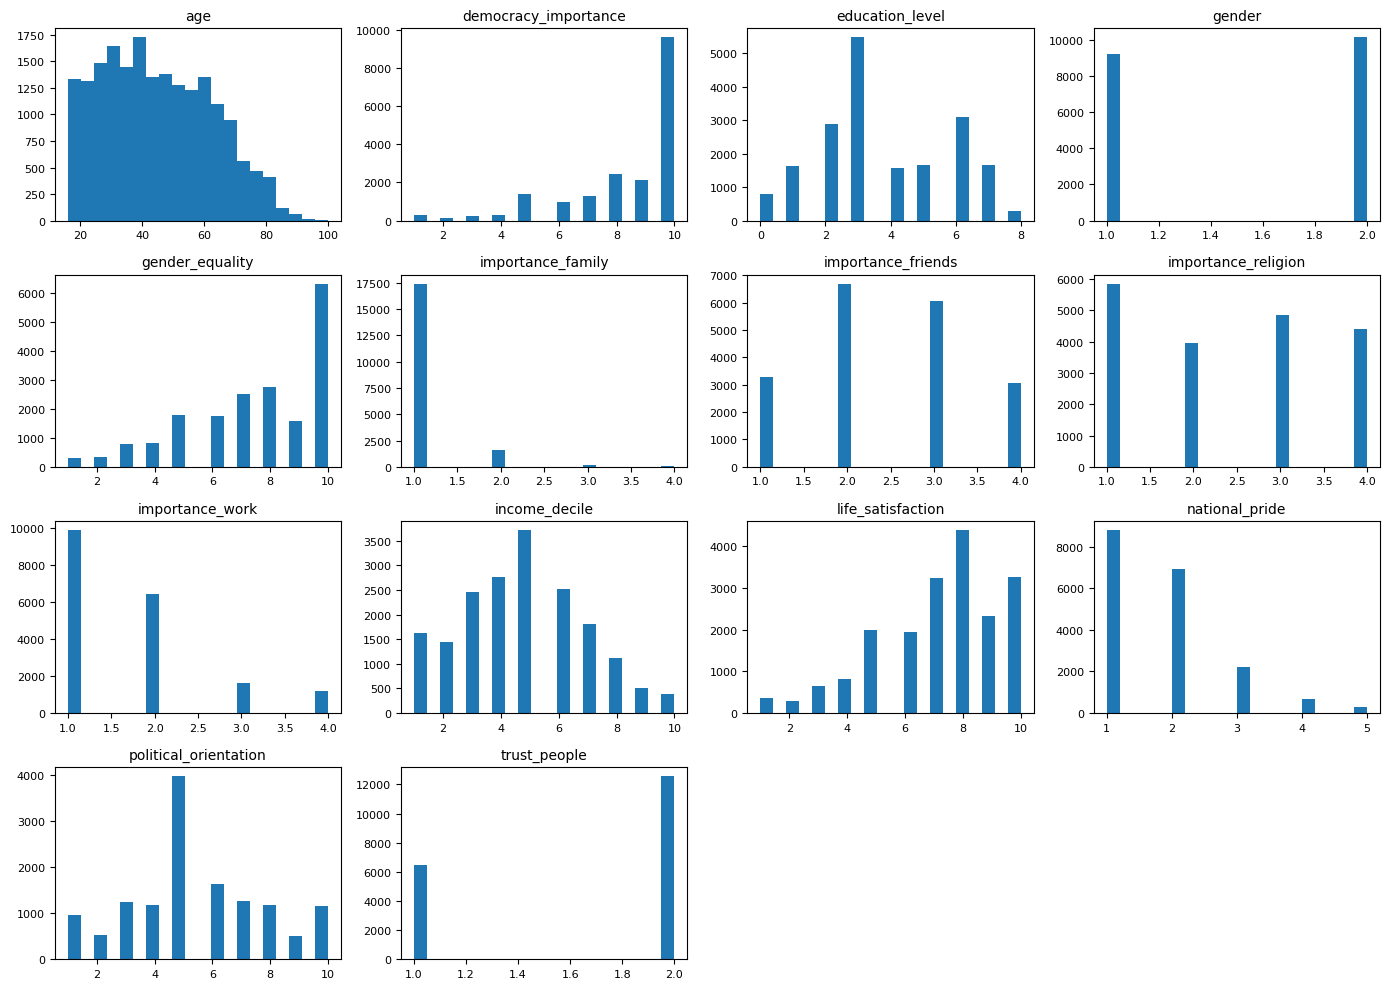

In [24]:

fig, axes = plt.subplots(4, 4, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(value_cols):
    axes[i].hist(df[col].dropna(), bins=20)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='both', labelsize=8)

# hide any unused axes
for j in range(len(value_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("eda_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

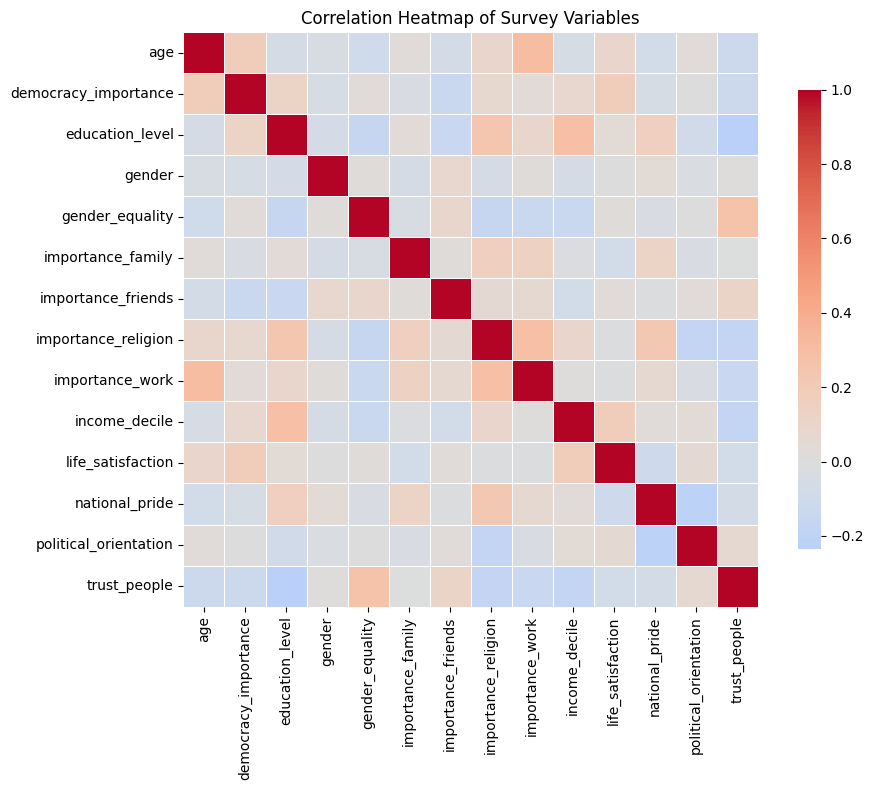

In [29]:
# correlation matrix using complete cases on analysis variables
df_complete = df.dropna(subset=value_cols).copy()
corr = df_complete[value_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap of Survey Variables")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", bbox_inches="tight")
plt.show()

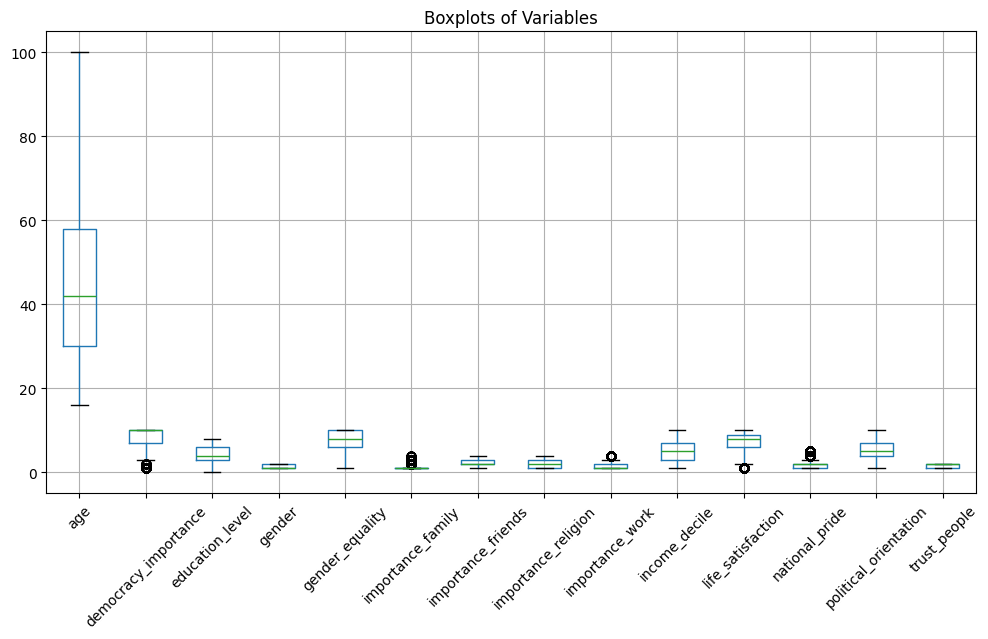

In [7]:
X.boxplot(figsize=(12,6), rot=45)
plt.title("Boxplots of Variables")
plt.show()

In [8]:
(df.isna().mean().sort_values(ascending=False) * 100)


political_orientation    29.544516
income_decile             5.045445
democracy_importance      3.253460
national_pride            2.447841
gender_equality           1.802314
education_level           1.606073
trust_people              1.585416
importance_religion       1.445982
importance_friends        1.301384
importance_work           1.105144
age                       0.738484
life_satisfaction         0.500930
importance_family         0.201405
gender                    0.170419
respondent_id             0.000000
country                   0.000000
dtype: float64

In [9]:
df.groupby("country")[value_cols].mean()

,age,democracy_importance,education_level,gender,gender_equality,importance_family,importance_friends,importance_religion,importance_work,income_decile,life_satisfaction,national_pride,political_orientation,trust_people
country,,,,,,,,,,,,,,
BRA,43.555366,8.179263,2.777970,1.545970,9.454754,1.169694,2.694220,1.735613,1.439704,4.018270,7.563284,2.230058,5.408200,1.933526
CHN,44.584980,8.772652,2.834331,1.549078,6.492552,1.145310,2.363244,3.248255,1.723750,4.147176,7.416667,1.642810,NaN,1.345630
DEU,50.797120,9.464474,4.078689,1.513743,5.583333,1.129011,2.191225,2.734560,1.799463,5.185889,7.737360,1.927395,4.764006,1.540486
GBR,51.816930,8.884373,4.250103,1.571040,6.996097,1.114867,2.413566,2.953210,2.106458,5.652476,7.317271,2.151515,4.972314,1.532918
IND,35.803783,8.449132,3.202487,1.433806,7.766366,1.070331,2.556569,1.558403,1.339667,5.439640,7.204384,1.308664,6.346600,1.823141
JPN,54.780488,8.704918,4.380703,1.563932,6.876923,1.082774,2.211464,3.255738,1.812261,4.185892,6.759398,1.844895,5.745902,1.644028
MEX,43.358252,8.306181,3.023081,1.497990,8.869465,1.035037,2.854347,1.848189,1.309770,4.228621,8.137356,1.382759,5.648802,1.897008
NGA,32.563460,7.926076,2.588762,1.488278,8.737055,1.015372,2.244281,1.079352,1.164216,4.411909,5.617314,1.431690,5.976068,1.873171
RUS,45.406630,7.377907,4.873333,1.587845,7.664564,1.185905,2.722160,2.457955,1.963252,4.773326,6.546518,1.653212,6.080968,1.760907


In [10]:
# Drop missing for PCA
df_pca = df.dropna()
X = df_pca[value_cols]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Eigenvalues (IMPORTANT: for correlation matrix PCA)
eigenvalues = pca.explained_variance_

# Variance explained
var_exp = pca.explained_variance_ratio_

# Cumulative variance
cum_var = np.cumsum(var_exp)

# Eigenvalue ratios (λ_k / λ_{k+1})
eig_ratio = eigenvalues[:-1] / eigenvalues[1:]
eig_ratio = np.append(eig_ratio, np.nan)  # last undefined

# Table
pca_table = pd.DataFrame({
    "Component": np.arange(1, len(eigenvalues)+1),
    "Eigenvalue": eigenvalues,
    "Variance Explained": var_exp,
    "Cumulative Variance": cum_var,
    "Eigenvalue Ratio": eig_ratio
})

pca_table



,Component,Eigenvalue,Variance Explained,Cumulative Variance,Eigenvalue Ratio
0,1,2.103688,0.150251,0.150251,1.366443
1,2,1.539535,0.109958,0.260208,1.120711
2,3,1.373713,0.098114,0.358323,1.234563
3,4,1.112712,0.079473,0.437795,1.024085
4,5,1.086543,0.077604,0.515399,1.032475
5,6,1.052367,0.075163,0.590562,1.184357
6,7,0.888556,0.063463,0.654025,1.092289
7,8,0.813481,0.058101,0.712126,1.070408
8,9,0.759972,0.054279,0.766405,1.049927
9,10,0.723834,0.051698,0.818103,1.027655


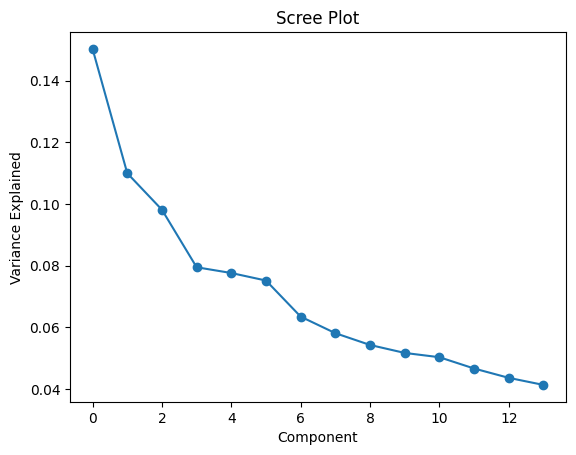

In [11]:
plt.plot(pca.explained_variance_ratio_, marker='o')
plt.title("Scree Plot")
plt.xlabel("Component")
plt.ylabel("Variance Explained")
plt.show()

Number of components to keep: 6


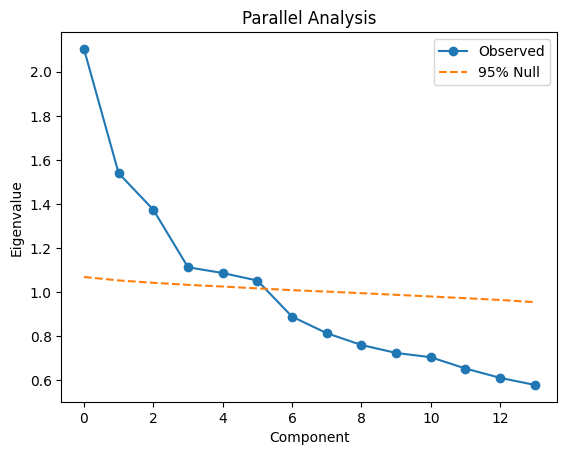

In [12]:
# Parallel Analysis
B = 500
n, p = X_scaled.shape
rng = np.random.default_rng(437)

null_eigvals = np.zeros((B, p))

for b in range(B):
    X_perm = np.empty_like(X_scaled)
    
    # shuffle each column independently
    for j in range(p):
        X_perm[:, j] = rng.permutation(X_scaled[:, j])
    
    # correlation matrix eigenvalues
    corr_perm = np.corrcoef(X_perm, rowvar=False)
    eigvals_perm = np.linalg.eigvalsh(corr_perm)[::-1]
    
    null_eigvals[b, :] = eigvals_perm

# Observed eigenvalues from correlation matrix
corr_obs = np.corrcoef(X_scaled, rowvar=False)
obs_eigvals = np.linalg.eigvalsh(corr_obs)[::-1]

# Null stats
null_mean = null_eigvals.mean(axis=0)
null_q95 = np.quantile(null_eigvals, 0.95, axis=0)

# Keep components where observed > 95th percentile null
significant = obs_eigvals > null_q95
n_keep = significant.sum()

print("Number of components to keep:", n_keep)

plt.plot(obs_eigvals, marker='o', label='Observed')
plt.plot(null_q95, linestyle='--', label='95% Null')

plt.title("Parallel Analysis")
plt.xlabel("Component")
plt.ylabel("Eigenvalue")
plt.legend()
plt.show()

In [13]:
# PCA loadings (properly scaled)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

pca_loadings = pd.DataFrame(
    loadings,
    index=value_cols,
    columns=[f"PC{i+1}" for i in range(len(pca.explained_variance_))]
)

# Show first few PCs (since we keep ~6)
pca_loadings.iloc[:, :6]



,PC1,PC2,PC3,PC4,PC5,PC6
age,0.276002,-0.234790,0.694808,-0.168986,0.105108,0.167772
democracy_importance,0.273776,-0.458992,0.124298,-0.037827,0.559228,-0.011369
education_level,0.596089,-0.066018,-0.407587,0.047414,0.017894,-0.111150
gender,-0.127538,0.150162,0.035639,0.524522,-0.039108,0.573564
gender_equality,-0.469860,0.039924,0.004319,0.114114,0.585151,-0.245965
importance_family,0.220159,0.371925,0.191598,-0.185438,-0.029491,-0.474094
importance_friends,-0.208660,0.289497,0.249761,0.642928,-0.138791,-0.269064
importance_religion,0.613491,0.319007,0.117544,0.138944,0.097757,-0.183421
importance_work,0.462773,0.180890,0.581194,0.112258,-0.096197,-0.020680
income_decile,0.408058,-0.344674,-0.391776,0.247256,-0.180736,-0.264148


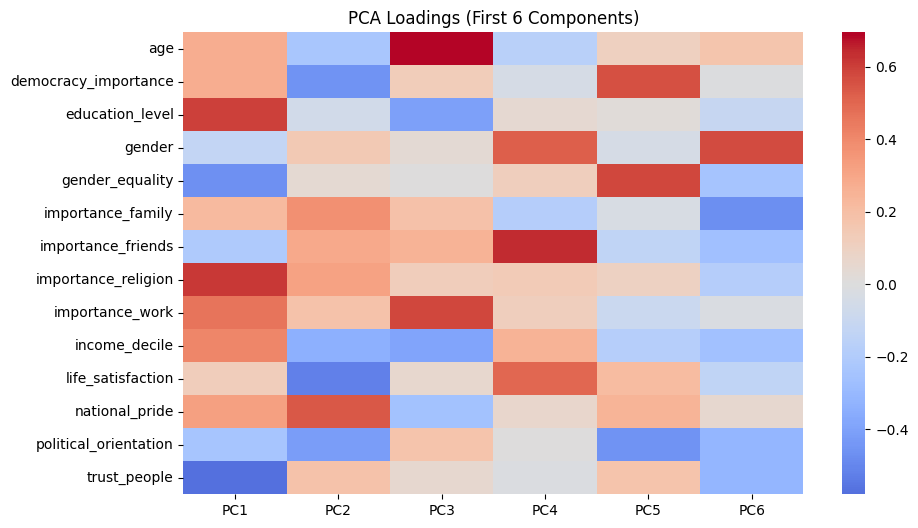

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(pca_loadings.iloc[:, :6], cmap="coolwarm", center=0)
plt.title("PCA Loadings (First 6 Components)")
plt.show()

In [15]:
k = 6

fa = FactorAnalyzer(n_factors=k, rotation='varimax')
fa.fit(X_scaled)

fa_loadings = pd.DataFrame(
    fa.loadings_,
    index=value_cols,
    columns=[f"Factor{i+1}" for i in range(k)]
)


fa_loadings

C:\Users\Anthony\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor1,Factor2,Factor3,Factor4,Factor5,Factor6
age,0.085723,0.652202,0.108666,0.128884,-0.094313,-0.083299
democracy_importance,-0.013586,0.181098,-0.006227,0.397723,0.035870,-0.209165
education_level,0.338250,-0.205695,0.220532,0.262684,0.199023,-0.210984
gender,-0.000347,0.015427,-0.126662,-0.040280,0.083853,0.203679
gender_equality,-0.547298,-0.063283,-0.075465,0.083636,0.018548,0.033349
importance_family,-0.004243,0.030547,0.328124,-0.106910,0.061157,-0.034406
importance_friends,-0.139898,-0.051500,0.141618,-0.001280,-0.070336,0.576714
importance_religion,0.211618,0.072281,0.484649,0.119773,0.301378,0.048996
importance_work,0.191265,0.360408,0.404150,0.026705,0.046220,0.121548
income_decile,0.312571,-0.244434,0.101265,0.350314,-0.076651,-0.110746


In [16]:
def align_signs(ref, target):
    aligned = target.copy()
    for col in ref.columns:
        if (ref[col] * target[col]).sum() < 0:
            aligned[col] = -aligned[col]
    return aligned

k = 6

fa_promax = FactorAnalyzer(n_factors=k, rotation='promax')
fa_promax.fit(X_scaled)

promax_loadings = pd.DataFrame(
    fa_promax.loadings_,
    index=value_cols,
    columns=[f"Factor{i+1}" for i in range(k)]
)
promax_aligned = align_signs(fa_loadings, promax_loadings)
promax_aligned

C:\Users\Anthony\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor1,Factor2,Factor3,Factor4,Factor5,Factor6
age,0.103598,0.695440,0.157630,-0.150384,0.117876,0.086793
democracy_importance,-0.139134,0.204823,0.451469,0.028473,0.171538,-0.076477
education_level,0.203428,-0.197556,0.187989,-0.134743,0.128079,-0.138852
gender,0.047408,-0.005909,-0.003015,0.139051,-0.190963,-0.094522
gender_equality,-0.659818,-0.074617,0.221678,-0.002834,-0.037776,-0.109629
importance_family,-0.060580,0.040676,-0.137603,-0.377410,0.022768,-0.015760
importance_friends,-0.156850,-0.088354,0.109550,-0.202359,-0.642640,0.101056
importance_religion,0.063169,0.075840,0.105872,-0.488431,-0.119905,-0.220329
importance_work,0.154018,0.379143,0.022857,-0.447931,-0.147975,0.025120
income_decile,0.214995,-0.236480,0.299080,-0.015737,0.004253,0.128991


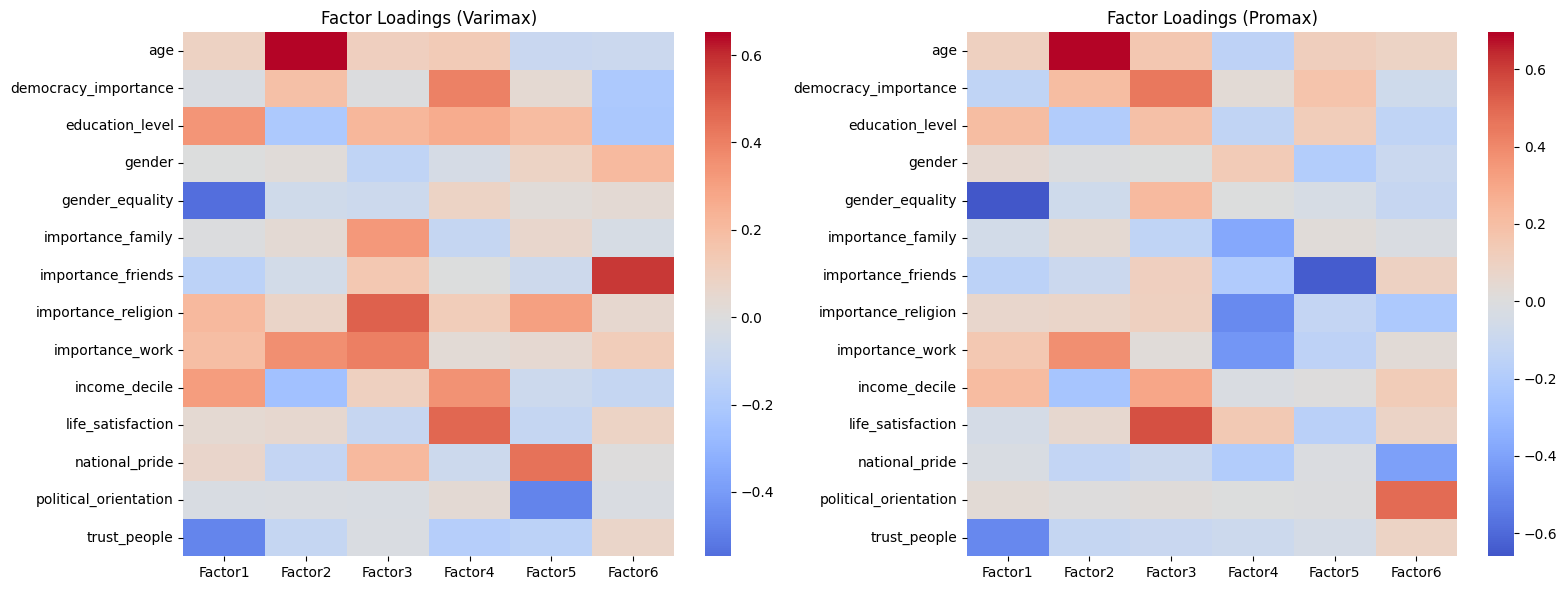

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Varimax
sns.heatmap(fa_loadings, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Factor Loadings (Varimax)")

# Promax
sns.heatmap(promax_aligned, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Factor Loadings (Promax)")

plt.tight_layout()
plt.show()

In [18]:

fa.get_communalities()

array([0.47696882, 0.23623942, 0.35848511, 0.06642009, 0.31768598,
       0.12497001, 0.37982712, 0.39246688, 0.34743712, 0.30856312,
       0.25429049, 0.25806281, 0.23261716, 0.29148747])

In [19]:
factor_scores = fa.transform(X_scaled)

df_factors = pd.DataFrame(
    factor_scores,
    columns=[f"Factor{i+1}" for i in range(6)]
)

df_factors["country"] = df_pca["country"].values

df_factors.groupby("country").mean()

C:\Users\Anthony\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor1,Factor2,Factor3,Factor4,Factor5,Factor6
country,,,,,,
BRA,-0.613771,-0.085110,-0.175568,-0.133061,0.090922,0.118017
DEU,0.511341,0.338094,0.131018,0.185886,0.186843,-0.161860
GBR,0.397471,0.266612,0.361455,0.237479,0.293876,-0.012376
IND,-0.100728,-0.378822,-0.298247,-0.066964,-0.416207,-0.020883
JPN,0.295857,0.480675,0.326465,0.033981,0.139516,-0.211936
MEX,-0.488843,-0.015136,-0.311915,0.061860,-0.255362,0.296174
NGA,-0.480132,-0.369669,-0.610296,-0.537722,-0.305715,-0.128441
RUS,0.149976,-0.092927,0.312843,-0.141835,-0.082735,0.119478
USA,0.146643,-0.067847,0.133384,0.084202,0.151192,-0.071360


In [20]:
k = 6  # same as FA for comparability

ica = FastICA(n_components=k, random_state=437, max_iter=1000)
X_ica = ica.fit_transform(X_scaled)

ica_components = pd.DataFrame(
    ica.components_.T,
    index=value_cols,
    columns=[f"IC{i+1}" for i in range(k)]
)

ica_components

,IC1,IC2,IC3,IC4,IC5,IC6
age,-0.237471,0.012096,-0.089434,-0.186230,-0.500778,0.064524
democracy_importance,0.063448,-0.181351,-0.214987,-0.436225,-0.190646,-0.265413
education_level,-0.131490,-0.030440,-0.130686,-0.053620,0.337965,-0.176151
gender,-0.160558,-0.355721,0.616132,0.008455,-0.048631,0.009464
gender_equality,0.468577,0.060960,0.027268,-0.347490,-0.062444,-0.238965
importance_family,0.036558,0.536506,-0.167516,-0.035570,0.041168,-0.007792
importance_friends,0.072192,0.260702,0.456281,-0.284556,0.214956,0.292045
importance_religion,-0.163424,0.289180,0.081027,-0.194490,0.098210,-0.158163
importance_work,-0.300632,0.264747,0.139579,-0.170120,-0.192993,0.116106
income_decile,-0.091970,-0.068214,-0.133517,-0.154294,0.488087,0.127224


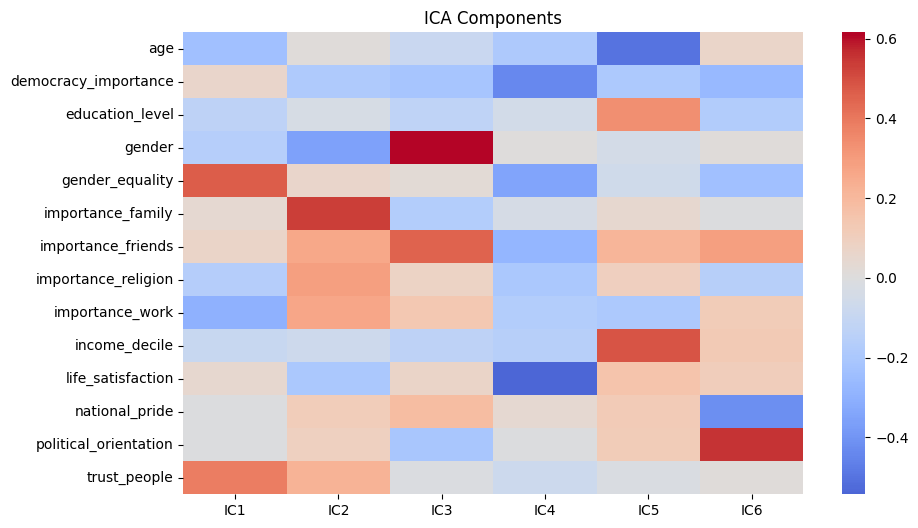

In [21]:
plt.figure(figsize=(10,6))
sns.heatmap(ica_components, cmap="coolwarm", center=0)
plt.title("ICA Components")
plt.show()

In [22]:
B = 20
components_list = []

for b in range(B):
    idx = np.random.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    X_sub = X_scaled[idx]
    
    ica = FastICA(n_components=5, random_state=437)
    ica.fit(X_sub)
    
    components_list.append(ica.components_)

components_array = np.array(components_list)

ref = components_array[0]

for i in range(1, B):
    corr = np.abs(np.corrcoef(ref.flatten(), components_array[i].flatten())[0,1])
    print(f"Run {i} similarity:", corr)

Run 1 similarity: 0.755434305477187
Run 2 similarity: 0.9955052848859852
Run 3 similarity: 0.2528771277875115
Run 4 similarity: 0.9812726929118903
Run 5 similarity: 0.15007252421338604
Run 6 similarity: 0.9353514146728737
Run 7 similarity: 0.2514401539627653
Run 8 similarity: 0.9951449768184307
Run 9 similarity: 0.2511163726913291
Run 10 similarity: 0.7668621343657397
Run 11 similarity: 0.9483998732179684
Run 12 similarity: 0.9309116247277405
Run 13 similarity: 0.2259193727144483
Run 14 similarity: 0.24892195985839924
Run 15 similarity: 0.9922617698332867
Run 16 similarity: 0.0343452535184819
Run 17 similarity: 0.2443805837820618
Run 18 similarity: 0.25222721504322615
Run 19 similarity: 0.1751215018101736


In [25]:
df_complete = df.dropna(subset=value_cols).copy()
X_complete = df_complete[value_cols]

C:\Users\Anthony\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


          Factor1   Factor2   Factor3   Factor4   Factor5   Factor6
country                                                            
BRA     -0.613771 -0.085110 -0.175568 -0.133061  0.090922  0.118017
DEU      0.511341  0.338094  0.131018  0.185886  0.186843 -0.161860
GBR      0.397471  0.266612  0.361455  0.237479  0.293876 -0.012376
IND     -0.100728 -0.378822 -0.298247 -0.066964 -0.416207 -0.020883
JPN      0.295857  0.480675  0.326465  0.033981  0.139516 -0.211936
MEX     -0.488843 -0.015136 -0.311915  0.061860 -0.255362  0.296174
NGA     -0.480132 -0.369669 -0.610296 -0.537722 -0.305715 -0.128441
RUS      0.149976 -0.092927  0.312843 -0.141835 -0.082735  0.119478
USA      0.146643 -0.067847  0.133384  0.084202  0.151192 -0.071360


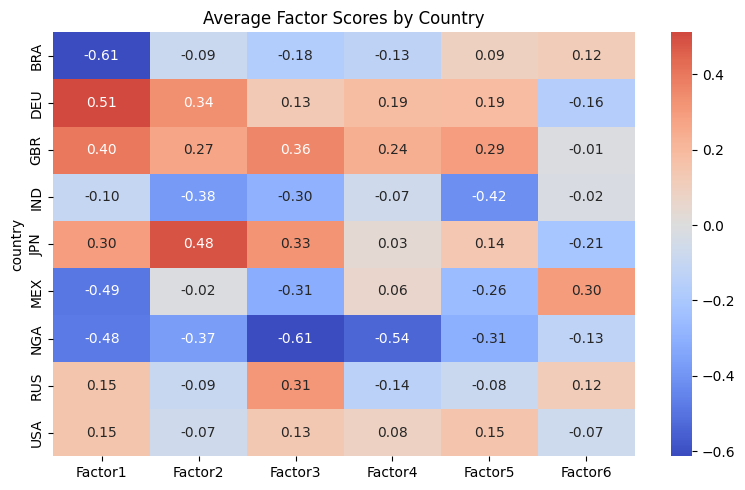

In [26]:
# Factor scores
fa_scores = fa.transform(X_scaled)

fa_score_df = pd.DataFrame(
    fa_scores,
    columns=[f"Factor{i+1}" for i in range(fa_scores.shape[1])]
)

fa_score_df["country"] = df_complete["country"].values

# Country-level means
fa_country_means = fa_score_df.groupby("country").mean()
print(fa_country_means)

# Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(fa_country_means, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Average Factor Scores by Country")
plt.tight_layout()
plt.savefig("fa_country_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

              IC1       IC2       IC3       IC4       IC5       IC6
country                                                            
BRA      0.818521  0.125958  0.270621 -0.099919 -0.166594 -0.247772
DEU     -0.798190 -0.138462 -0.166319 -0.154377 -0.161276 -0.233321
GBR     -0.734363  0.090102  0.113350 -0.330194  0.013723 -0.319701
IND      0.436369 -0.181464 -0.292983  0.253534  0.334755  0.517740
JPN     -0.662037  0.160360 -0.214383 -0.051523 -0.416756 -0.162938
MEX      0.709602 -0.149729  0.221919 -0.306863 -0.152035  0.349525
NGA      0.898828 -0.326242 -0.166115  0.877236 -0.192688  0.242263
RUS     -0.238739  0.396665  0.163632  0.192088  0.262749  0.298433
USA     -0.191170  0.059381 -0.050814 -0.038779  0.177152 -0.210238


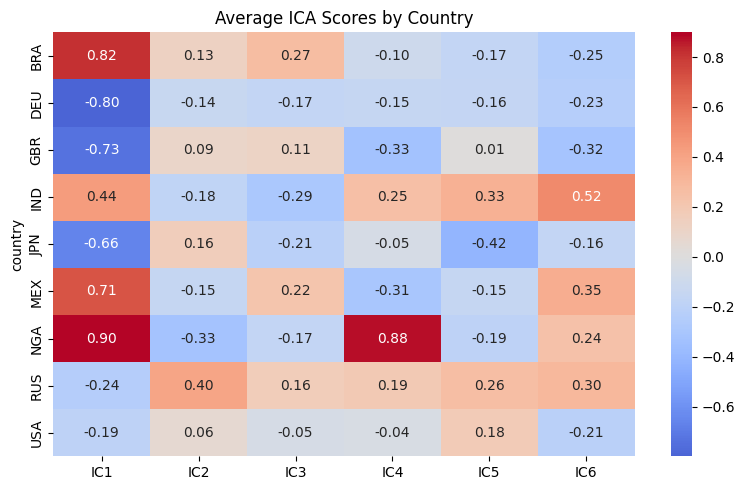

In [27]:
# ICA scores
ica_score_df = pd.DataFrame(
    X_ica,
    columns=[f"IC{i+1}" for i in range(X_ica.shape[1])]
)

ica_score_df["country"] = df_complete["country"].values

# Country-level means
ica_country_means = ica_score_df.groupby("country").mean()
print(ica_country_means)

# Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(ica_country_means, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Average ICA Scores by Country")
plt.tight_layout()
plt.savefig("ica_country_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

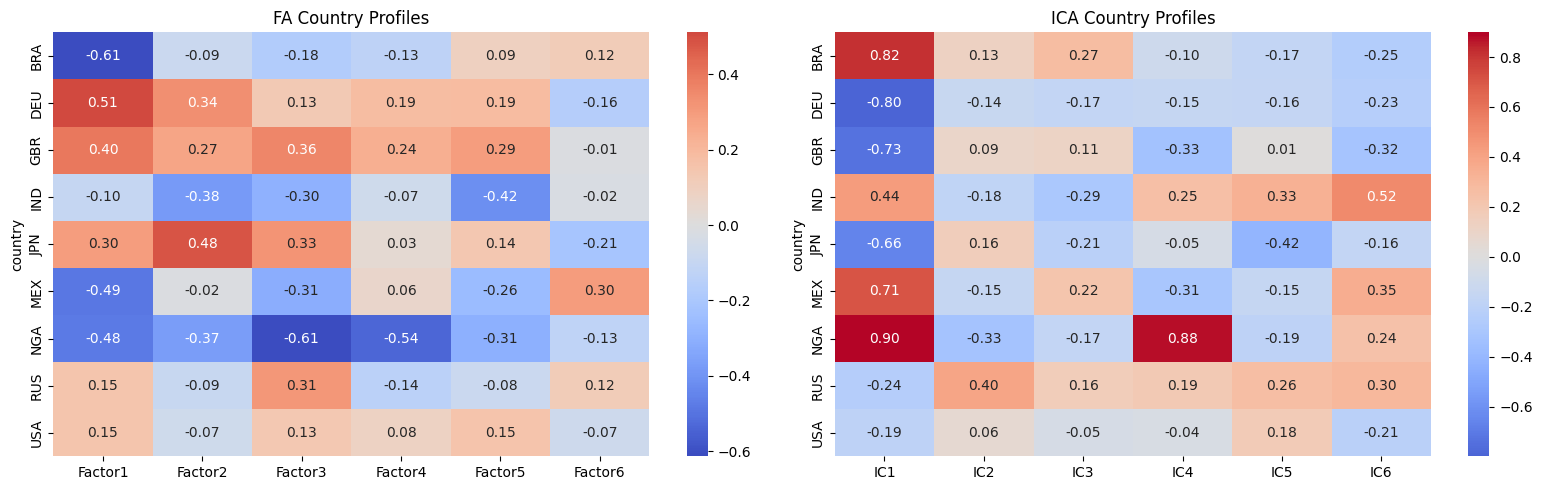

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(fa_country_means, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("FA Country Profiles")

sns.heatmap(ica_country_means, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("ICA Country Profiles")

plt.tight_layout()
plt.savefig("country_profiles_fa_ica.png", dpi=300, bbox_inches="tight")
plt.show()